# Performance
![performance.png](../images/performance.png)

In [1]:
from sentropy import sentropy
MEASURES =["alpha", "rho", "beta", "gamma", "normalized_alpha",\
"normalized_rho", "normalized_beta"]

## Row-by-row streaming
Here we demonstrate that streaming the matrix row-by-row on the fly is more efficient than calculating an entire similarity matrix separately.  
The example used here is the BloodMNIST dataset (@medmnistv2), which should take ~30s to download.  
Device used: Mac Mini

In [2]:
import numpy as np
from medmnist import BloodMNIST
from joblib import Parallel, delayed

In [3]:
def rmse_sim(vec1, vec2):
    '''
    Similarity function used by sentropy (exp(-RMSE)).
    '''
    rmse = np.sqrt(np.mean((vec1 - vec2) ** 2))
    return np.exp(-rmse)

def compute_similarity(i, j, X):
    '''
    Parallelization function
    '''
    return i, j, rmse_sim(X[i], X[j])


def get_similarity_matrix(X, n_jobs=-1):
    '''
    Parallelized calculation of similarity matrix
    '''
    n = len(X)
    similarity = np.eye(n)

    # Generate upper-triangle index pairs
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]

    results = Parallel(n_jobs=n_jobs)(
        delayed(compute_similarity)(i, j, X)
        for i, j in pairs
    )

    for i, j, sim in results:
        similarity[i, j] = sim
        similarity[j, i] = sim

    return similarity


def block_based(X):
    '''
    calculating similarity matrix separately
    '''
    similarity = get_similarity_matrix(X, n_jobs=-1)
    sentropy(label_ind, similarity=similarity, q=[0, 1, 1.5, np.inf], measure=MEASURES)


def row_based(X):
    '''
    row-by-row calculation
    '''
    sentropy(label_ind, similarity=rmse_sim, sfargs=X, q=[0, 1, 1.5, np.inf], measure=MEASURES)

In [4]:
# loading dataset
test_dataset = BloodMNIST(split="test", download=True)

# Extract images
X = np.array([np.array(img) for img, label in test_dataset])

# Flatten images: (N, H, W, C) -> (N, H*W*C)
X = X.reshape(len(X), -1).astype(np.float32)

# creating class (label) dictionary
labels = np.array([x[0] for _, x in test_dataset])
label_ind = {}
for label in set(labels):
    label_ind[label] = labels == label

In [5]:
%%timeit
block_based(X)

9.33 s ± 263 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [6]:
%%timeit
row_based(X)

5.35 s ± 60.2 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


## Performance benchmark
Here we benchmark the speed for running sentropy with different settings

In [2]:
import numpy as np
big_counts = np.random.randint(101, size=(10000,100))

n = 10000
indices = np.triu_indices(n, k=1)
values = np.random.rand(len(indices[0]))
big_sim_matrix = np.zeros((n, n))
big_sim_matrix[indices] = values
big_sim_matrix = big_sim_matrix + big_sim_matrix.T
np.fill_diagonal(big_sim_matrix, 1.0)

### Device 1: Mac Mini
64GB 14-core M4 Pro chip

In [3]:
%%timeit
sentropy(big_counts, similarity=big_sim_matrix, q=[0,1, 1.5, np.inf], measure=MEASURES)

795 ms ± 85.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [4]:
%%timeit
sentropy(big_counts, similarity=big_sim_matrix, q=[0,1, 1.5, np.inf], measure=MEASURES, backend='torch')

200 ms ± 1.78 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [5]:
%%timeit
sentropy(big_counts, similarity=big_sim_matrix, q=[0,1, 1.5, np.inf], measure=MEASURES, backend='torch', device='mps')

132 ms ± 14.8 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


### Device 2: PC 
128GB 24-core AMD Ryzen Threadripper PRO 4.2GHz with 2 NVIDIA RTX 6000 Ada Generation GPUs (96GB VRAM)

In [3]:
%%timeit
sentropy(big_counts, similarity=big_sim_matrix, q=[0,1, 1.5, np.inf], measure=MEASURES)

393 ms ± 22.3 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [4]:
%%timeit
sentropy(big_counts, similarity=big_sim_matrix, q=[0,1, 1.5, np.inf], measure=MEASURES, backend='torch')

209 ms ± 17.9 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [5]:
%%timeit
sentropy(big_counts, similarity=big_sim_matrix, q=[0,1, 1.5, np.inf], measure=MEASURES, backend='torch',  device='cuda')

89.1 ms ± 567 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


## Visiualization

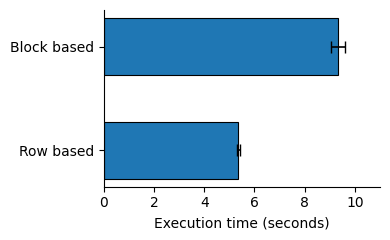

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

methods = ["Block based", "Row based"]
times = [9.33, 5.35]
errors = [0.263, 0.0602]

fig, ax = plt.subplots(figsize=(4, 2.5))

y = np.arange(len(methods))

ax.barh(
    y,
    times,
    xerr=errors,
    capsize=4,
    height=0.55,
    edgecolor="black",
    linewidth=0.8,
    error_kw={"elinewidth": 1.2}
)

ax.set_yticks(y)
ax.set_yticklabels(methods)
ax.set_xlabel("Execution time (seconds)")
ax.set_xlim(0, 11)

ax.invert_yaxis()
sns.despine()
plt.tight_layout()
plt.savefig('row.pdf')

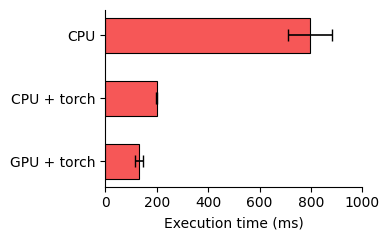

In [20]:
methods = ["CPU", "CPU + torch", "GPU + torch"]
times = [795, 200, 132]
errors = [85.8, 1.78, 14.8]

fig, ax = plt.subplots(figsize=(4, 2.5))

y = np.arange(len(methods))

ax.barh(
    y,
    times,
    xerr=errors,
    capsize=4,
    height=0.55,
    color="#F65757",
    edgecolor="black",
    linewidth=0.8,
    error_kw={"elinewidth": 1.2}
)

ax.set_yticks(y)
ax.set_yticklabels(methods)
ax.set_xlabel("Execution time (ms)")
ax.set_xlim(0, 1000)


ax.invert_yaxis()
sns.despine()
plt.tight_layout()
plt.savefig('Mac.pdf')

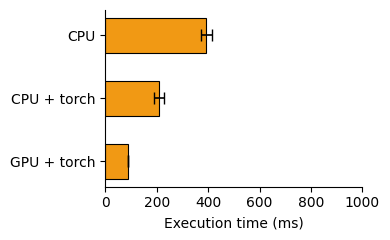

In [21]:
methods = ["CPU", "CPU + torch", "GPU + torch"]
times = [393, 209, 89.1]
errors = [22.3, 17.9, 0.567]  # 567 μs = 0.567 ms

fig, ax = plt.subplots(figsize=(4, 2.5))

y = np.arange(len(methods))

ax.barh(
    y,
    times,
    xerr=errors,
    capsize=4,
    height=0.55,
    color="#F19914",
    edgecolor="black",
    linewidth=0.8,
    error_kw={"elinewidth": 1.2}
)

ax.set_yticks(y)
ax.set_yticklabels(methods)
ax.set_xlabel("Execution time (ms)")
ax.set_xlim(0, 1000)

ax.invert_yaxis()
sns.despine()
plt.tight_layout()
plt.savefig('Ubuntu.pdf')

## Reference
@article{medmnistv2,
    title={MedMNIST v2-A large-scale lightweight benchmark for 2D and 3D biomedical image classification},
    author={Yang, Jiancheng and Shi, Rui and Wei, Donglai and Liu, Zequan and Zhao, Lin and Ke, Bilian and Pfister, Hanspeter and Ni, Bingbing},
    journal={Scientific Data},
    volume={10},
    number={1},
    pages={41},
    year={2023},
    publisher={Nature Publishing Group UK London}
}